# 06. Задержки METAR и исключение COR

Методика: бинарная классификация GoA фиксированным логистическим
классификатором L2 C=1, обученным ранее на сценарии 15 минут с COR.
Повторного fit нет. Преобразования и пороги validation заморожены.
Меняется только погодный вход для тех же 546577 test-событий.

Сценарии: задержки 0, 15, 30 минут; без COR при 15 минутах. Максимальная
давность 60 минут, доступность строго до C40. При исключении COR выбирается
последнее оставшееся сообщение, а не просто блокируется прежняя связь.
Неоднозначность времени определяется по исходному архиву до исключения COR.
Все 26 полей получают те же числовые маски и правила проверенного ядра.
Отсутствие сообщения не удаляет событие. Это допущения доступности,
а не подтвержденные времена получения исторической погоды.


In [1]:
from pathlib import Path
import hashlib,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE=Path.cwd()/'research/weather-model-comparison'
m=json.loads((BASE/'reports/06_weather_scenario_manifest.json').read_text())
assert m['verified'] and m['primary_reproduced'] and not m['fit_executed'] and not m['thresholds_retuned']
for entry in m['files']:
    with (BASE/'data/weather_sensitivity_v1'/entry['file']).open('rb') as f:assert hashlib.file_digest(f,'sha256').hexdigest()==entry['sha256']
summary=pd.read_csv(BASE/'reports/06_weather_scenario_summary.csv')
thresholds=pd.read_csv(BASE/'reports/06_weather_scenario_thresholds.csv')
display(summary);display(thresholds)
assert summary.rows.eq(546577).all() and summary.GoA.eq(1739).all()
assert summary.loc[summary.scenario.eq('primary_reproduction'),'information_changed'].eq(0).all()


,scenario,rows,GoA,AP,ROC_AUC,Brier,weather_usable,information_changed,probability_changed
0,primary_reproduction,546577,1739,0.006679,0.608395,0.003168,546038,0,0
1,delay0,546577,1739,0.006700,0.613080,0.003168,546440,269189,269189
2,delay30,546577,1739,0.006664,0.606686,0.003168,545546,270702,270702
3,no_cor,546577,1739,0.006495,0.608055,0.003168,473236,75069,75069


,scenario,target_validation_FPR,TP,FP,FN,TN,recall,FPR,precision
0,primary_reproduction,0.001,14,442,1725,544396,0.008051,0.000811,0.030702
1,primary_reproduction,0.005,79,3932,1660,540906,0.045428,0.007217,0.019696
2,primary_reproduction,0.010,120,8236,1619,536602,0.069005,0.015116,0.014361
3,delay0,0.001,10,436,1729,544402,0.005750,0.000800,0.022422
4,delay0,0.005,81,3913,1658,540925,0.046578,0.007182,0.020280
5,delay0,0.010,123,8277,1616,536561,0.070730,0.015192,0.014643
6,delay30,0.001,13,454,1726,544384,0.007476,0.000833,0.027837
7,delay30,0.005,81,3899,1658,540939,0.046578,0.007156,0.020352
8,delay30,0.010,113,8172,1626,536666,0.064980,0.014999,0.013639
9,no_cor,0.001,13,383,1726,544455,0.007476,0.000703,0.032828


## Проверка воспроизведения и изменения качества

Основной сценарий 15 минут заново выбран из архива. Все 26 модельных
полей совпали с исходным модельным снимком, вероятности — с сохраненными
прогнозами до 1e-12. Это проверяет согласованность альтернативной сборки.
Доли изменения информации и вероятностей используют все test-события.
Пороги не выбираются заново; фактическая FPR может отличаться между сценариями.


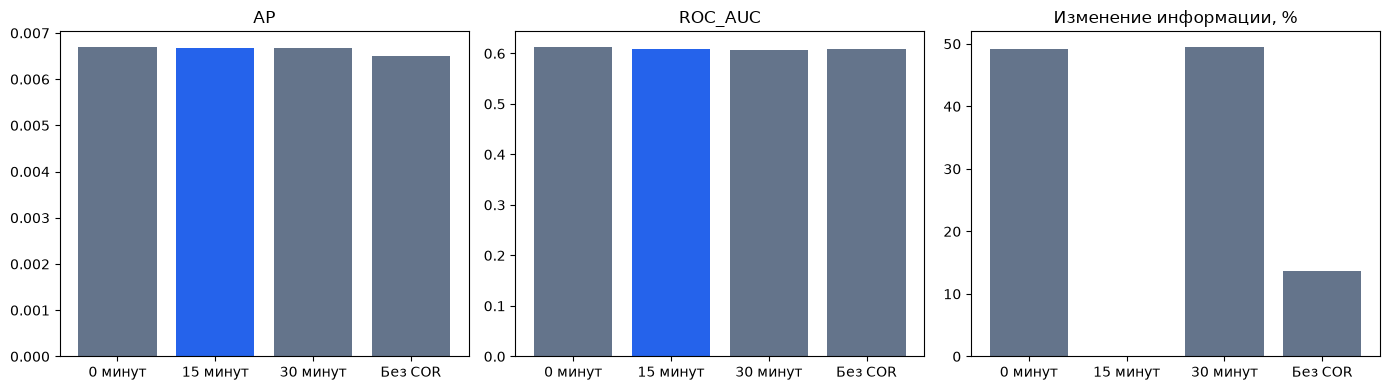

In [2]:
order=['delay0','primary_reproduction','delay30','no_cor']
plot=summary.set_index('scenario').loc[order]
labels=['0 минут','15 минут','30 минут','Без COR']
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,metric in zip(axes,['AP','ROC_AUC','information_changed']):
    values=plot[metric].to_numpy()
    if metric=='information_changed':values=100*values/546577
    ax.bar(labels,values,color=['#64748b','#2563eb','#64748b','#64748b'])
    ax.set_title(metric if metric!='information_changed' else 'Изменение информации, %')
fig.tight_layout()
for ext in ['png','svg']:
    p=BASE/f'figures/06_delay_cor_sensitivity.{ext}'
    fig.savefig(p,dpi=160,bbox_inches='tight')
    if ext=='svg':p.write_text('\n'.join(s.rstrip() for s in p.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')
plt.show()


## Ограничения

Это проверка фиксированной модели при изменении входа, а не сравнение
моделей, заново обученных на каждом сценарии. Test уже использовался;
выбирать по этим результатам лучший сценарий для подтверждающей оценки нельзя.
Основная пара, дневные интервалы, абляция типа и зазор рассмотрены отдельно.
Низкая полнота GoA и переносимость порогов ограничивают практический вывод.
